# Mining Amazon reviews: preprocessing, clustering, recommendation and sentiment

Five product categories of the [Amazon Reviews 2023](https://amazon-reviews-2023.github.io/)
dataset: All Beauty, Software, Musical Instruments, Handmade Products and Gift Cards.

1. **Data and preprocessing**: loading, sampling, text cleaning
2. **Exploratory analysis**: ratings, frequent and distinctive words, ratings over time, best and worst products
3. **Sentiment scores**: VADER on the review text, combined with the stars
4. **Product clustering**: TF-IDF + LSA + k-means on the product texts
5. **Recommendation**: collaborative, content-based and hybrid, evaluated on held-out reviews
6. **Sentiment classification**: negative / neutral / positive from the review text

The code lives in `src/reviews_mining/`; this notebook runs it and shows the results.
Every step caches its output under `data/processed/`, so only the first run is slow.

In [1]:
%matplotlib inline
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from reviews_mining import (cache, classify, clustering, config, data, eda, recommend,
                            sentiment, text)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
KEYS = list(config.CATEGORIES)
print("data directory:", config.DATA_DIR)

data directory: /home/stratis/Documents/Uni/S_2025/DataMining/amazon-reviews-mining/data


## 1. Data and preprocessing

Each category has two files: reviews (one per line) and product metadata. The review file
is read once: a uniform random sample of 100,000 reviews keeps the full text, and every
review contributes its user, product, stars and date to a ratings table (used for the
rating statistics, the ratings over time and the recommender, which need all reviews).

Missing prices are kept as missing. Filling them with the mean would give most products
the same price and hide the real price differences.

In [2]:
reviews_raw = {k: data.load_reviews(k) for k in KEYS}
ratings = {k: data.load_ratings(k) for k in KEYS}
meta_raw = {k: data.load_metadata(k) for k in KEYS}

overview = pd.DataFrame({k: {
    "reviews": len(ratings[k]),
    "reviews in the sample": len(reviews_raw[k]),
    "users": ratings[k]["user_id"].nunique(),
    "products": len(meta_raw[k]),
    "% products with a price": 100 * meta_raw[k]["price"].notna().mean(),
    "% products without description": 100 * (meta_raw[k]["description"].map(len) == 0).mean(),
} for k in KEYS}).T.round(1)
del reviews_raw, meta_raw   # the cleaned versions are loaded next; free the memory
overview

,reviews,reviews in the sample,users,products,% products with a price,% products without description
allBeauty,701528.0,100000.0,631986.0,112590.0,15.7,83.0
software,4880181.0,100000.0,2589466.0,89251.0,79.5,4.6
musicalInstruments,3017439.0,100000.0,1762679.0,213593.0,39.7,28.5
handmadeProducts,664162.0,100000.0,586613.0,164817.0,59.2,14.5
giftCards,152410.0,100000.0,132732.0,1137.0,33.4,23.0


Most users write very few reviews: the number of distinct users is 53% (Software) to 90%
(All Beauty) of the number of reviews. That matters for the recommender in section 5. Product
metadata is patchy: only 16% of beauty products have a price, and 83% have no description,
which is why the product text used later combines title, description and feature bullets.

**Text cleaning.** Lowercase; remove URLs, mentions, digits, punctuation and emoji; drop
stop words; keep the lemmas of 3 to 15 letters. Review title and text are cleaned
together; for products, the title, description and feature bullets. Lemmas come from
spaCy's lookup tables, without a part-of-speech tagger: about half a million words per
second in one process, so all five categories take minutes.

In [3]:
reviews = {k: sentiment.load_scored_reviews(k) for k in KEYS}   # cleaning + VADER, cached
meta = {k: text.load_clean_metadata(k) for k in KEYS}

reviews["allBeauty"][["rating", "text", "text_clean"]].head(5)

,rating,text,text_clean
0,5.0,"This spray is really nice. It smells really good, goes on really fine, and does the trick. I will say it feels like ...",lovely scent overpower spray nice smell good fine trick feel like need lot texture want lot hair medium thickness co...
1,5.0,great chapstick but it does still melt in cars will in my center console,great chap stick great chapstick melt car center console
2,5.0,"Smells good, feels great!",yes smell good feel great
3,1.0,I can't give an honest review just yet but I wanted to tell my thoughts after receiving this wig. The package came ...,inch honest review want tell thought receive wig package come day big plus head town want quickly package nice old b...
4,1.0,Was a gift and arrived busted so I couldn't give it to her,poor ship gift arrive bust couldn


## 2. Exploratory analysis

allBeauty            mean rating 3.96 over 701,528 reviews
software             mean rating 3.94 over 4,880,181 reviews
musicalInstruments   mean rating 4.26 over 3,017,439 reviews
handmadeProducts     mean rating 4.50 over 664,162 reviews
giftCards            mean rating 4.55 over 152,410 reviews


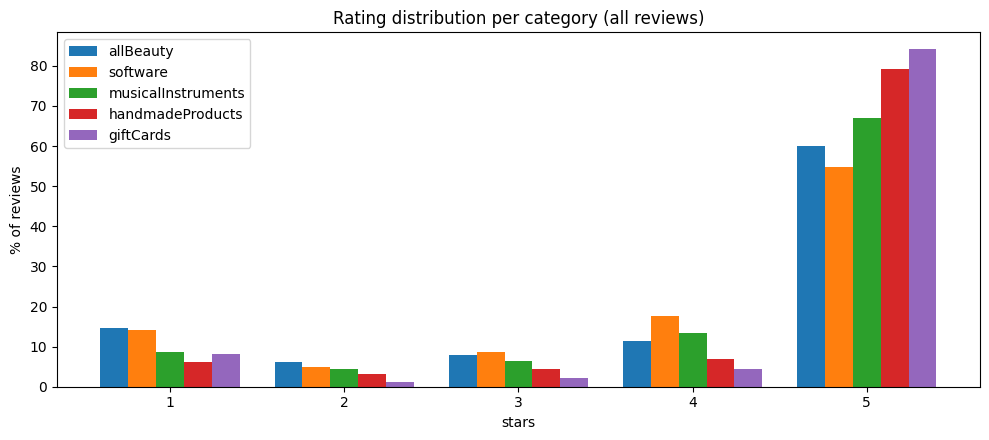

In [4]:
shares = eda.plot_rating_distributions(ratings)
plt.show()

Ratings are J-shaped: 5 stars dominate (55% of Software reviews, 84% of Gift Cards), and
1 star is more common than 2 or 3 stars in every category (in All Beauty and Gift Cards it
is the second most common rating). People mostly review when they are very happy or very
unhappy. Average
ratings range from 3.94 (Software) to 4.55 (Gift Cards).

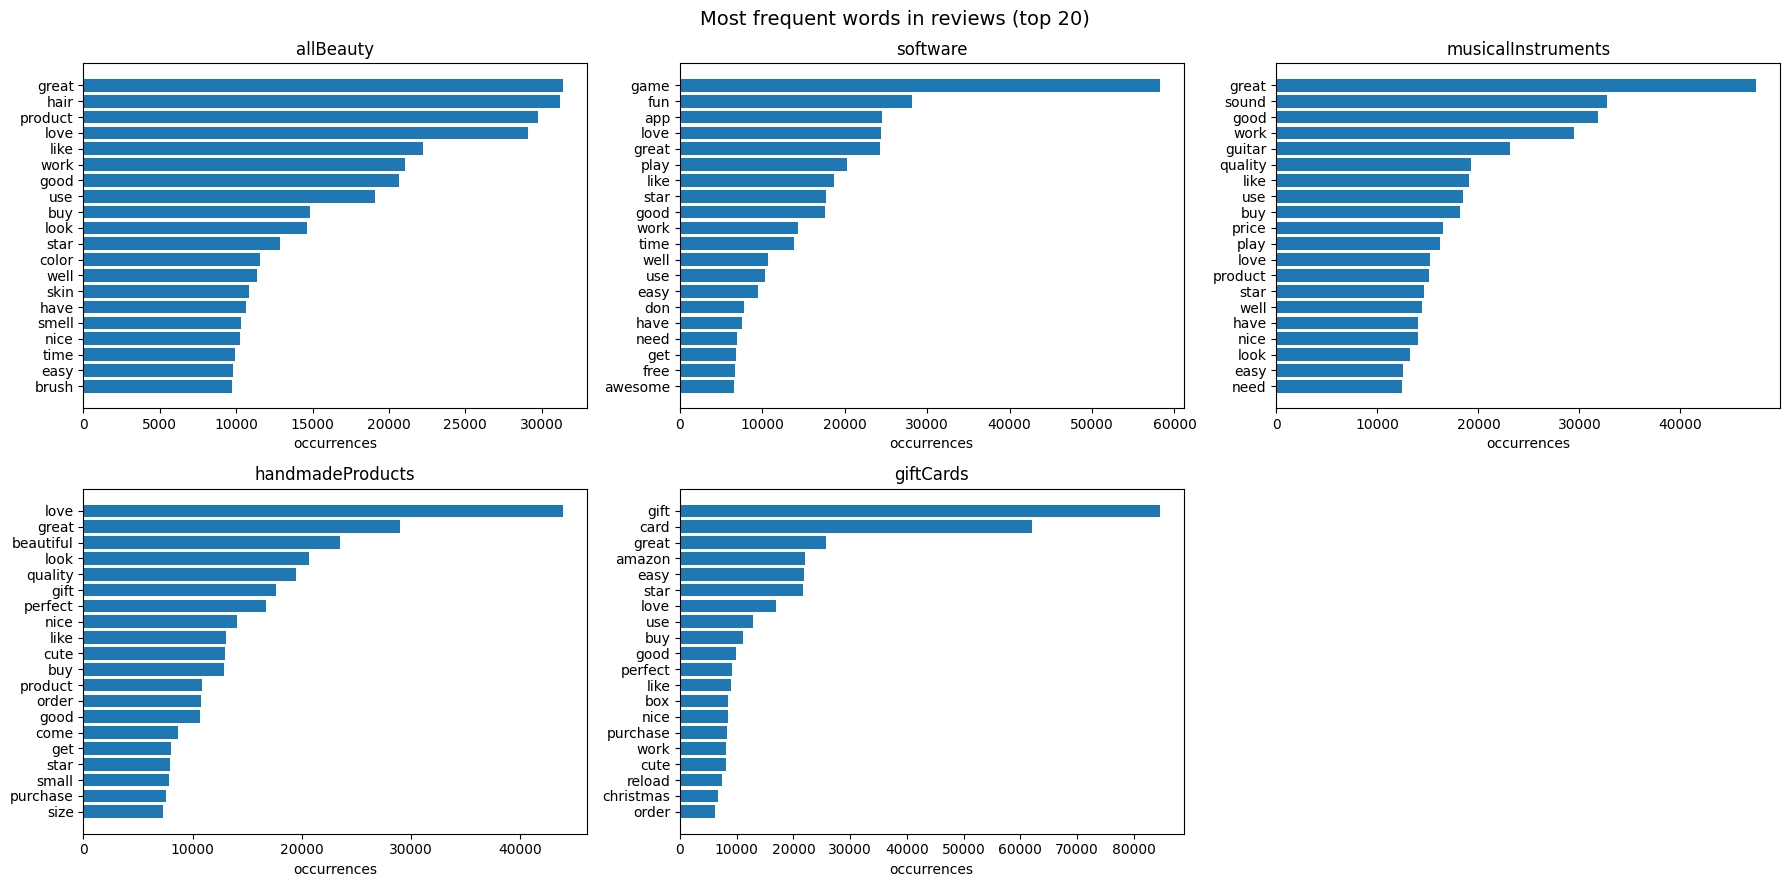

In [5]:
eda.plot_top_tokens(reviews)
plt.show()

Raw frequencies are dominated by words every review uses. The words that differ most
between negative (1-2 stars) and positive (4-5 stars) reviews, ranked by log-odds ratio,
say more about what customers complain about and what they praise:

In [6]:
pd.concat({k: eda.distinctive_words(reviews[k], n=12) for k in KEYS}, axis=1)

allBeauty                 software            musicalInstruments              handmadeProducts               giftCards           
      negative    positive     negative   positive           negative     positive         negative     positive   negative   positive
0   returnable   excelente    defective     fluenz                doa    excelente             poor      perfect  worthless  excelente
1       dinero  pleasantly          vpc  addictive         unreliable   pleasantly           poorly         stun    dispute      peasy
2         mala    perfecto  unwatchable     addict               scam     perfecto             scam   thoughtful   inactive    perfect
3      garbage     encanta    worthless    awesome               mala        study            waste  exceptional     ripoff    brainer
4         scam      themed         bait        luv              waste        hubby        embarrass       superb    deceive    delight
5          smh   excellent   unreliable  excelente            garbage     excelent         terrible       obsess       bait       love
6         junk   amazingly        awful      lover               junk     hesitate          garbage    excellent  embarrass     sturdy
7       policy   versatile     unusable     awsome          worthless        plush         horrible      delight   horrible    awesome
8    worthless      exceed        greed     superb                rma    excellent            awful        amaze    mislead  excellent
9        waste     changer     terrible    provoke             refund        beefy       dissatisfy       outfit       scam      lover
10        poor     regimen     existent      notch             poorly      ovation            false  outstanding      false       neat
11    unusable       yummy         scam    delight           horrible  exceptional        deceptive     treasure     beware   excelent

Negative reviews are about things not working and feeling cheated: *defective*, *doa*,
*unusable*, *unreliable*, *scam*, *worthless*, *refund*, *junk*. Positive ones praise
quality: *excellent*, *exceptional*, *superb*, *outstanding*, *sturdy*. Some words are
specific to a category: *inactive*, *dispute* and *bait* for gift cards that didn't work,
*unwatchable* for streaming software. Spanish-language reviews show up on both sides
(*excelente*, *perfecto* / *mala*, *dinero*): they are few but strongly polarized.

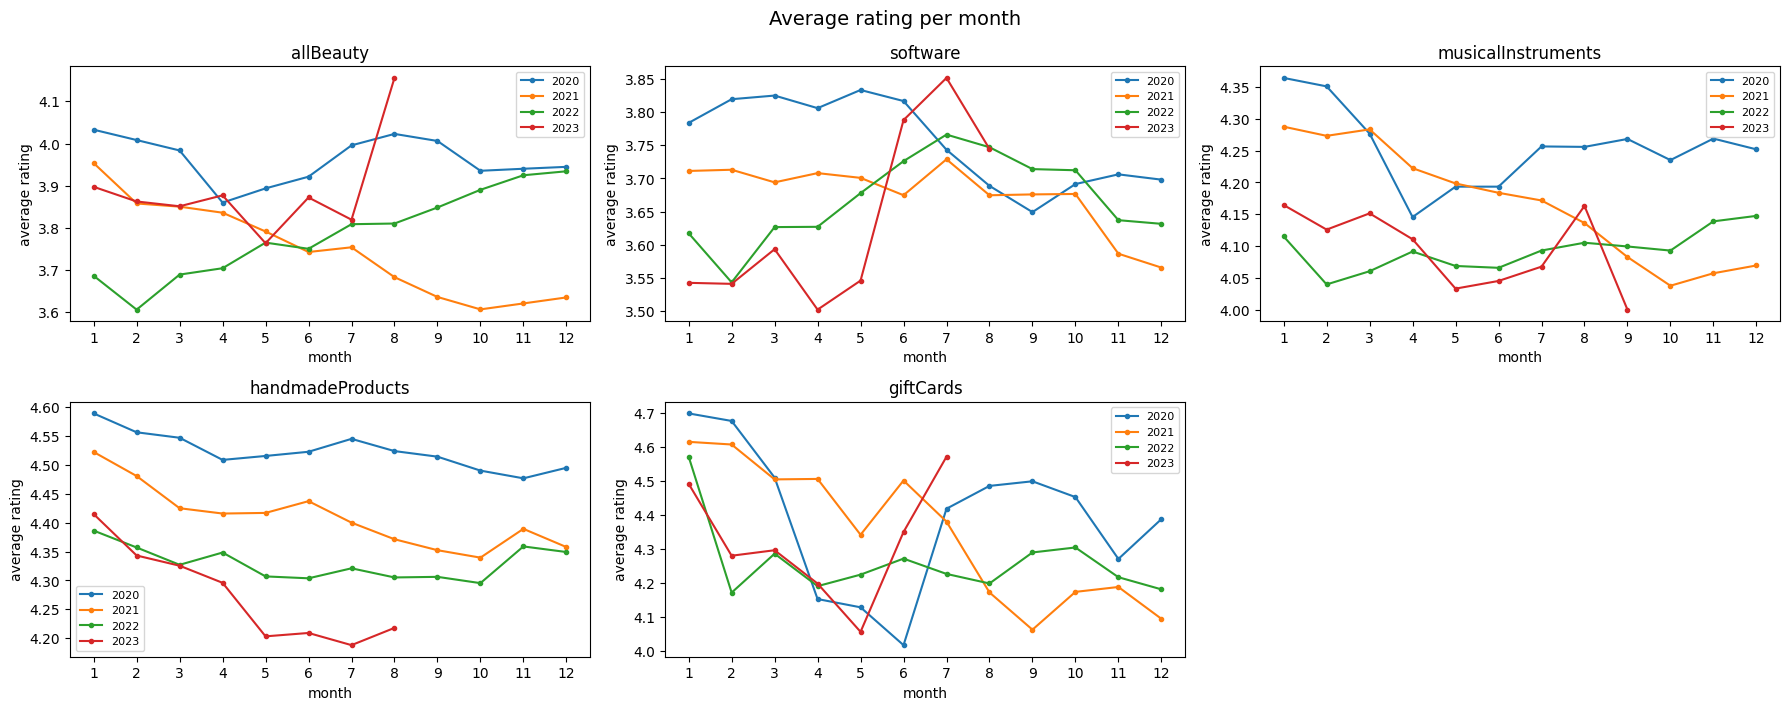

In [7]:
eda.plot_monthly_ratings(ratings, min_reviews=200)
plt.show()

There is no consistent seasonal pattern from month to month, but there is a trend across
years: in Handmade Products, Musical Instruments and Software, ratings in 2022-2023 are
lower than in 2020 (Handmade from about 4.5 to about 4.3, Musical Instruments from about
4.25 to about 4.1).

**Best and worst products.** The number of ratings is used as a proxy for sales. The
worst products are the lowest-rated among products with at least 1,000 ratings, so that
a product with three bad reviews doesn't count as the worst.

In [8]:
for k in KEYS:
    print(f"\n=== {k} ===")
    print("Most rated:")
    display(eda.best_products(meta[k]))
    worst = eda.worst_products(meta[k], min_ratings=1000)
    print("Lowest rated with at least 1,000 ratings:" if len(worst) else
          "No product with at least 1,000 ratings.")
    if len(worst):
        display(worst)


=== allBeauty ===
Most rated:


,title,average_rating,rating_number
0,"Elle 18 Eye Drama Kajal, Bold Black, 0.35 g",4.2,30206
1,"Maybelline New York Colossal Bold Eyeliner, Black, 3g",4.3,27308
2,JIMIRE Fake Eyelashes Fluffy Volume 3D Faux Mink Eyelashes Natural Lashes Pack 5 Pairs,4.4,16062
3,"THE ORDINARY Niacinamide 10% + Zinc 1% 30ml, 1.01 Fl Oz (Pack of 1)",4.5,15264
4,Pro by Oral-B 2500 3D White Pink Toothbrush with Case,4.7,14700


Lowest rated with at least 1,000 ratings:


,title,average_rating,rating_number
0,Allnice Magnetic Eyelashes Dual Magnets False Eyelashes Reusable 3D No Glue 3 Fake Lashes Extension with Tweezers fo...,2.5,2368
1,"2 PCS Green Tea/Eggplant Purifying Clay Stick Mask, Face Moisturizes Oil Control, Deep Clean Pore, Improves Skin,for...",2.8,1479
2,"Dr. Barbara Sturm 2 Pairs Silicone Winged Eyeliner Stamp, Lazy Eye Shadow Applicator Silicon wing eyeliner Eyeshadow...",2.9,1434
3,American International Industries Clean + Easy Deluxe Electrolysis Home for Coarse Hair,3.0,1687
4,"Magnetic Eyelashes, Magnetic Eyeliner, Magnetic Eyeliner and Lashes Kit,4 pairs of false eyelashes with Eyelash Tweezer",3.2,1599



=== software ===
Most rated:


...

,title,average_rating,rating_number
0,Tiny Silver Double Hoop Nose Ring - Spiral Nose Ring 20 Gauge Snug Double Nose Piercing Thin Nose Piercings Hoops,3.3,1183
1,"Helix Cartilage Piercing - 20G Sterling Silver Helix Piercing Ear Ring - Cartilage Earring, Silver Cartilage Hoop",3.6,2746
2,Tiny Silver Nose Ring hoop - 24 gauge snug Nose Hoop thin nose Piercings hoops - nose piercing rings,3.8,6198
3,"Double Nose Ring Hoop for Single Piercing, 14k Gold Filled or Sterling Silver Spiral Twist Nose Hoop for Women Men (...",3.8,4287
4,Stress & Anxiety Relief Aromatherapy Nasal Inhaler - Personal Diffuser Sniffer Stick with Pure Undiluted Organic Ess...,3.8,3651



=== giftCards ===
Most rated:


,title,average_rating,rating_number
0,Amazon.com Gift Card in a Holiday Gift Box (Various Designs),4.9,185606
1,Amazon Reload,4.7,143309
2,Amazon.com Gift Card in a Mini Envelope,4.9,105948
3,Amazon.com Gift Card in Various Gift Boxes,4.9,104005
4,Amazon.com Gift Card in a Reveal (Various Designs),4.9,80974


Lowest rated with at least 1,000 ratings:


,title,average_rating,rating_number
0,Spotify Gift Card,4.5,1912
1,Visa $200 Gift Card (plus $6.95 Purchase Fee),4.6,15723
2,$200 Mastercard Gift Card (plus $6.95 Purchase Fee),4.6,5313
3,Amazon Reload,4.7,143309
4,Visa $50 Gift Card (plus $4.95 Purchase Fee),4.7,35871


Best sellers are cheap, everyday products (eyeliners, guitar strings, gift cards), and in
Software they are streaming apps: YouTube alone has 1.9 million ratings. The worst-rated
popular products are gimmicks that don't deliver: magnetic eyelashes, guitar-chord
trainers, "X-ray scanner" apps. In Gift Cards, even the lowest-rated popular card averages
4.5 stars; the Visa and Mastercard cards there come with a purchase fee.

## 3. Sentiment scores

VADER scores the sentiment of the original text (it uses capitals, punctuation and
negations, so it doesn't run on the cleaned text). The score is combined with the
normalized stars using three weightings. How well does the text alone agree with the
stars?

In [9]:
display(pd.DataFrame({k: sentiment.vader_agreement(reviews[k]) for k in KEYS}).round(3))
display(sentiment.mean_vader_by_stars(reviews).round(3))
reviews["allBeauty"][["rating", "rating_normalized", "vader"] + sentiment.score_columns()].head().round(3)

,allBeauty,software,musicalInstruments,handmadeProducts,giftCards
correlation,0.672,0.626,0.612,0.704,0.473
agreement (1-2 vs 4-5 stars),0.868,0.869,0.885,0.938,0.875
"positive text, 1-2 stars",0.037,0.036,0.027,0.017,0.029
"negative text, 4-5 stars",0.008,0.009,0.008,0.003,0.006


,allBeauty,software,musicalInstruments,handmadeProducts,giftCards
stars,,,,,
1.0,0.405,0.427,0.403,0.410,0.525
2.0,0.524,0.527,0.522,0.546,0.610
3.0,0.651,0.659,0.647,0.661,0.675
4.0,0.811,0.817,0.815,0.838,0.784
5.0,0.873,0.859,0.869,0.915,0.846


,rating,rating_normalized,vader,score_0.7_0.3,score_0.5_0.5,score_0.3_0.7
0,5.0,1.0,0.963,0.974,0.981,0.989
1,5.0,1.0,0.812,0.869,0.906,0.944
2,5.0,1.0,0.941,0.959,0.971,0.982
3,1.0,0.0,0.888,0.621,0.444,0.266
4,1.0,0.0,0.474,0.332,0.237,0.142


Reviews where the text and the stars disagree most strongly:

In [10]:
r = reviews["allBeauty"]
print("Positive text, 1 star:")
display(r[(r["rating"] == 1)].nlargest(3, "vader")[["rating", "vader", "text"]])
print("Negative text, 5 stars:")
display(r[(r["rating"] == 5)].nsmallest(3, "vader")[["rating", "vader", "text"]])

Positive text, 1 star:


,rating,vader,text
92695,1.0,0.99935,"This claims to be titanium dioxide free, gluten free, made with natural and organic ingredients, vegan, and free of ..."
2389,1.0,0.99835,"Update 3/17: I have been buying these nails since Oct 2020, and I have absolutely loved them, unfortunately this rec..."
40659,1.0,0.99785,UPDATE:<br />My wand broke! Tip is stuck inside! I really loved this mascara but if I can't use it... it's useless...


Negative text, 5 stars:


,rating,vader,text
71809,5.0,0.00835,I have ordered three units and each time they have been different.. most recent the worst almost to tears for the mo...
64977,5.0,0.01590,"I rushed ordered this clay for my husband who was experiencing a horrible, itchy rash. It helped to take the insani..."
52479,5.0,0.02275,Only problem we had with this head is the absolute fear it strikes in the bottom of your soul when it has been left ...


VADER agrees with the stars on 87-94% of the clearly positive or negative reviews, and its
average score rises steadily with the stars (0.4-0.5 at 1 star, 0.85-0.9 at 5). The
correlation is lowest for Gift Cards (0.47), whose reviews are short ("Great gift").
Disagreements are mostly mixed reviews: 1-star reviews that open with praise ("I have
absolutely loved them, unfortunately..."), and 5-star reviews that describe the problem the
product solved ("a horrible, itchy rash"). Text that reads positive under a 1-2 star
rating is more common (2-4%) than the opposite (under 1%): complaints are often polite.

## 4. Product clustering

Each product's text → TF-IDF → truncated SVD (LSA, 100 dimensions) → k-means, with k
chosen by the silhouette score. Price and rating are not clustering inputs: they are used
afterwards to describe each cluster (see `src/reviews_mining/clustering.py` for why).


=== allBeauty: k = 10 ===


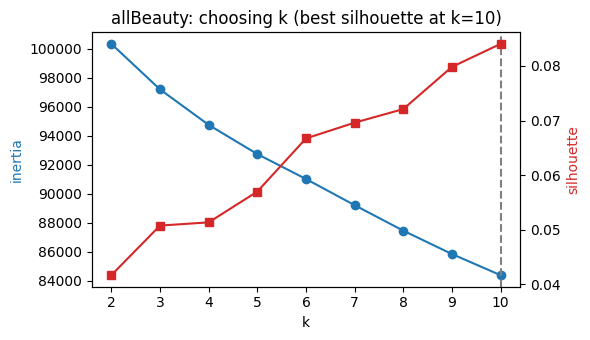

,products,top terms,price known,median price,mean rating,% rated < 3.5,median #ratings
cluster,,,,,,,
0,7573,"wig, lace, hair, woman, synthetic, human, black, inch",5%,23.99,3.51,42.73,8.0
1,9412,"nail, polish, art, gel, manicure, acrylic, tip, pcs",16%,10.78,3.85,24.95,11.0
2,9324,"hair, extension, braid, inch, human, crochet, clip, synthetic",4%,19.04,3.50,42.54,6.0
3,13707,"makeup, lip, eye, eyebrow, powder, brush, cosmetic, foundation",18%,14.99,3.95,23.60,9.0
4,25126,"hair, brush, comb, tattoo, set, man, style, woman",17%,14.95,3.94,22.59,11.0
5,15729,"pack, spray, soap, body, oil, ounce, bottle, fragrance",28%,22.00,4.22,12.88,8.0
6,9503,"hair, headband, girl, woman, accessory, clip, band, elastic",7%,9.99,4.04,17.11,10.0
7,5344,"bundle, hair, human, brazilian, virgin, wave, closure, unprocessed",1%,41.25,3.16,54.17,4.0
8,12429,"skin, cream, face, oil, facial, moisturize, anti, natural",27%,19.99,4.05,18.05,14.0


cluster 0: Kinky Straight Wig Human Hair Lace Front Wig Pre Plucked Bleached Knots Light Yaki Straigh | Queentas Ombre Ash Pink Wig Short Bob Straight Middle Part Synthetic Hair Wig Cosplay Part | Lace Wig Band Cap 2- In- One Lace Wig Band With Wig Cap By Hairline And Part For Seamless  | Straight Human Hair Wigs with Bangs None Lace Wigs Glueless Machine Made Wigs for Black Wo
cluster 1: conisy Water-Based Non-Toxic Peel-Off Nail Polish for Lady and Girls (Black) | 192 Pieces 8 Boxes Short Oval Press on False Nails Square False Nails with Rhinestone Glos | SANTEE 3 Pcs Color Mirror Effect Metallic No UV LED Nail Polish Bold Lacquer + Free ZipBag | NAIL ANGEL 100pcs/bag Nail Art AB color Crystal Gem 20 Different Shapes Rhinestone Gem 100
cluster 2: 5packs Goddess Locs Crochet Hair 18 Inch River Fauxs Locs Wavy Crochet With Curly Hair In  | 2 Pcs Clip in Bangs Human Hair Extensions Clip on Fringe Neat Bangs Straight Hairpiece Fla | RONX_shelly Professional Hair Extensions Tool Hair Conn

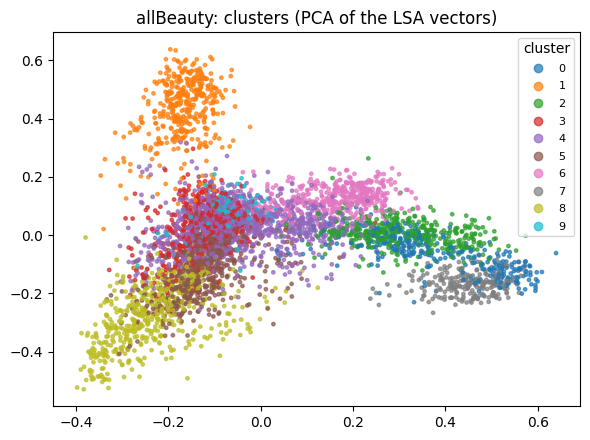


=== software: k = 9 ===


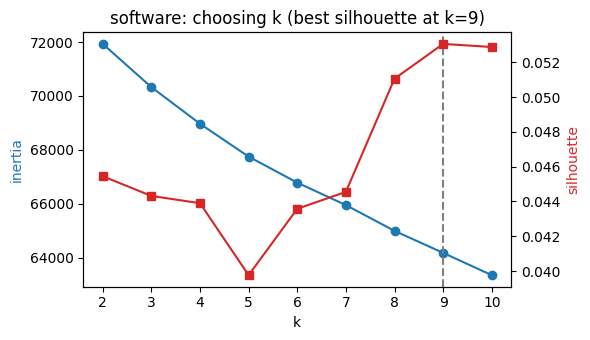

,products,top terms,price known,median price,mean rating,% rated < 3.5,median #ratings
cluster,,,,,,,
0,6765,"puzzle, game, hide, object, find, solve, level, play",97%,0.00,3.44,47.54,17.0
1,7856,"game, car, have, simulator, enemy, race, drive, fight",96%,0.00,3.31,61.14,27.0
2,8845,"kid, game, fun, color, child, girl, dress, play",95%,0.00,3.41,49.37,20.0
3,15261,"window, software, file, system, create, include, mac, tool",20%,19.95,3.29,55.67,6.0
4,9421,"learn, word, language, lesson, child, practice, skill, read",62%,0.00,3.45,45.94,6.0
5,7337,"news, app, video, stream, live, radio, content, watch",95%,0.00,3.53,42.09,16.0
6,1592,"slot, casino, machine, vega, bonus, jackpot, win, game",98%,0.00,3.16,69.72,17.0
7,20166,"app, use, phone, device, application, android, free, easy",95%,0.00,3.27,58.98,11.0
8,12000,"game, play, level, score, fun, challenge, match, mode",98%,0.00,3.36,53.77,14.0


cluster 0: Word Trip : Word Stack Puzzle | GraphiLogic "10x10" Puzzles | Crucigramas (Spanish Crossword Puzzles) | Patterns: Jigsaw Puzzle
cluster 1: Monsters | Wood Cargo Transporter | Road Trip Action | Bank Robbery - Grand Theft
cluster 2: Pet Island - Animal Shelter | Virtual Families 2: Our Dream House | Dip Recipes | Guide for Broken Age
cluster 3: Microsoft Visio 2003 Standard OLD VERSION | Backup Now! Deluxe | Microsoft Entourage X for Mac [OLD VERSION] | Microsoft Windows 7 Ultimate Upgrade
cluster 4: Fire Inspection and Code Enforcement Exam Prep 8th Ed. | Learn Microsoft Excel 2007 Fast with Step by step training | Learn Muscles: Anatomy | eMedia Singing For Dummies Deluxe (2 volume set)
cluster 5: Mystery Movies & TV by Fawesome | Real World News | NCAA Football Scores & Alerts | Hockey Docs
cluster 6: Red White and Blue Fortune Jackpot Galaxy Doubledown Slots - Multi Reel and Wheel Real Cla | Empire Jackpot Vegas Slots - Best Free Casino Games For Huge Win | Big Slots - 20

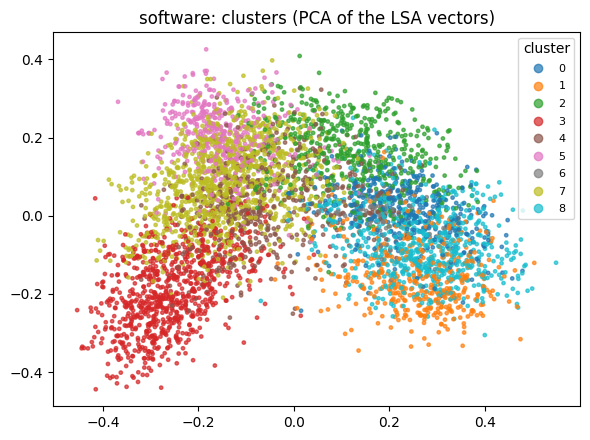


=== musicalInstruments: k = 9 ===


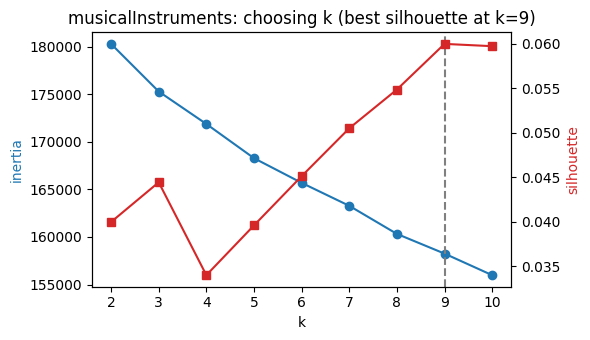

,products,top terms,price known,median price,mean rating,% rated < 3.5,median #ratings
cluster,,,,,,,
0,38821,"guitar, string, pick, electric, acoustic, bass, set, screw",46%,14.99,4.20,12.83,9.0
1,26796,"pedal, power, effect, control, input, output, speaker, audio",36%,149.99,4.14,15.04,9.0
2,18295,"neck, body, guitar, maple, fingerboard, rosewood, mahogany, pickup",23%,279.99,4.25,13.69,4.0
3,20140,"microphone, mic, wireless, record, condenser, audio, system, noise",40%,47.00,4.05,15.17,17.0
4,9610,"cable, xlr, connector, male, female, shield, foot, audio",43%,19.73,4.38,8.14,10.0
5,26785,"strap, case, pad, leather, bag, guitar, adjustable, foam",39%,41.86,4.25,11.92,10.0
6,21427,"drum, cymbal, percussion, inch, stick, sound, snare, mallet",43%,48.47,4.31,10.88,8.0
7,9729,"light, lead, power, dmx, party, stage, adapter, remote",41%,28.28,4.02,19.31,8.0
8,41970,"key, piano, instrument, violin, mouthpiece, reed, size, play",42%,24.00,4.13,16.20,8.0


cluster 0: C. B. Gitty's High Quality Guitar Fretting/Fret Slotting Saw - 18TPI - Made in the USA! | V-PICKS Euro Smokey Mountain | OEM Guitar Pickups ISYS Plus EQ Tuner Piezo Pickup Equalizer System TOP QUALITY Acoustic G | L-OO Acoustic Guitar Layout Template - Guitar Building
cluster 1: ADA GCS-5 Natural Resonance Guitar Cabinet Simulation and DI A/DA Cab Sim w/Cle | Casio Privia PX160 PACK3 Digital Piano TMS Stage Essentials Bundle- Black | One Control Dimension Blue Monger Modulation Effect Pedal | Alesis Monitor1 MKII Channel Studio Monitor (passive)
cluster 2: Ovation Elite TX 1778TX-5 Mid Depth Acoustic Guitar Black | Kepma Guitar One with Premp Large (Black Stain) d1ce BKM | Ibanez S-Series S470DXQM Guitar Red Viking w/ Hard Case | Full Size 39" Inch ZEBRA Electric Guitar & Gig Bag, Strap, Cable, and 10 Watt Amplifier Co
cluster 3: MAXDORIA 3 in 1 Wireless Lavalier Microphone for iPhone,Android,Camera and Laptop, 2.4G Ul | Hosa MHR-422 Microphone Clip, Rubber, 22 mm | InnoGear

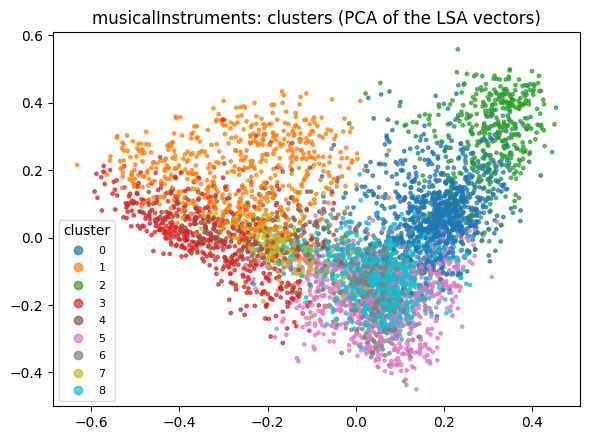


=== handmadeProducts: k = 9 ===


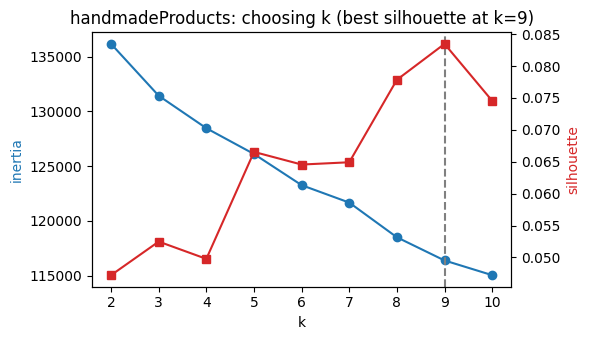

,products,top terms,price known,median price,mean rating,% rated < 3.5,median #ratings
cluster,,,,,,,
0,5390,"oil, scent, soap, fragrance, skin, natural, essential, ingredient",50%,14.95,4.26,12.88,5.0
1,13336,"earring, ear, silver, sterling, stud, wire, jewelry, gold",56%,22.00,4.45,9.05,4.0
2,9378,"decal, sticker, vinyl, apply, wall, window, car, laptop",71%,9.99,4.47,6.82,7.0
3,61236,"gift, personalize, wood, inch, color, ornament, sign, custom",57%,21.00,4.55,6.69,4.0
4,8479,"ring, silver, sterling, gold, jewelry, size, stone, band",60%,40.00,4.22,15.44,4.0
5,10130,"bracelet, bead, bangle, charm, wrist, silver, adjustable, jewelry",59%,24.95,4.39,10.19,4.0
6,22180,"print, art, frame, wall, decor, unframed, paper, poster",70%,15.00,4.51,5.90,7.0
7,17340,"shirt, cotton, fabric, wash, size, dry, towel, soft",52%,19.99,4.50,7.40,4.0
8,17347,"necklace, pendant, chain, silver, sterling, jewelry, gift, charm",61%,29.99,4.43,8.98,4.0


cluster 0: Peanut Butter Cookies - Scented All Natural Soy Wax Melts - 6 Cube Clamshell 3.2oz Highly  | Essential Oil Diffuser Necklace | Boho Necklace | Aromatherapy Jewelry | Terracotta Diffus | LaJAshley Strengthening Hair Elixir, Oil Based, Vegan, All Natural, Circulates Blood Flow, | Hair Growth Oil, Sea Moss Hair Growth Oil, Hair Oil For Damaged, Dry and Frizzy Hair, Heal
cluster 1: Scarab beetle crystal earrings. Sterling silver. Made w/Swarovski Elements. | 10mm Champagne Glass Pearl Earrings | Hematite Heart Earrings Fuchsia Pink Rose | Silver-tone Frosted Metallic Stripe Stud Earrings 12mm (Clear AB)
cluster 2: Hope inspirational quote sticker | Be hopeful decal by swaygirls for a hydro flask, laptop | Set of (2) Black Diamond Climbing Car Window Vinyl Decal Sticker. Comes in different sizes | 2 Lane Clamp w Start Gate (Compatible with Hot Wheels Cars and Track) (Blue/Orange) | Kitchen Rules Wall Art - Vinyl Decal, Home Kitchen Decor, Restaurant Decoration, Wall Deco
cluster 

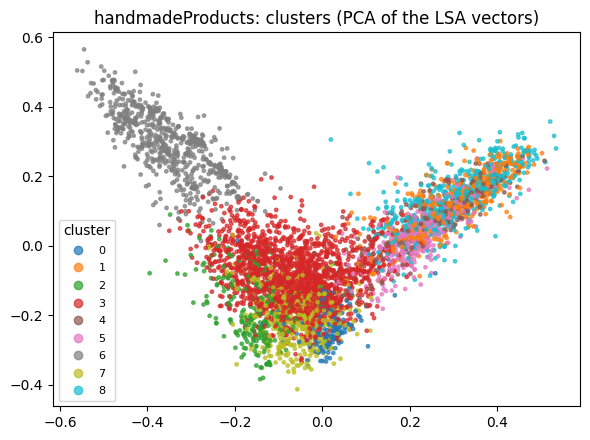


=== giftCards: k = 3 ===


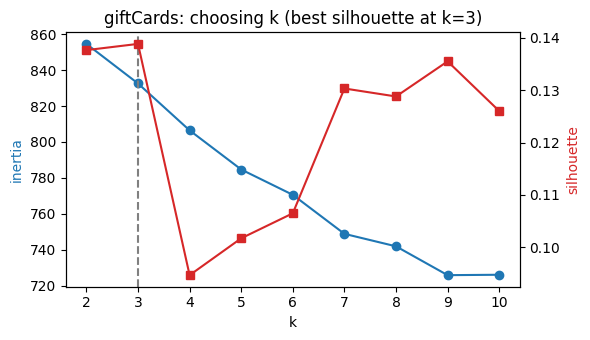

,products,top terms,price known,median price,mean rating,% rated < 3.5,median #ratings
cluster,,,,,,,
0,687,"online, redemption, instore, location, store, restaurant, food, purchase",51%,45.0,4.47,7.42,107.0
1,358,"amazon, com, item, million, pack, redeemable, storewide, free",9%,25.0,4.61,5.03,603.0
2,92,"forward, freight, company, method, product, payment, greet, store",2%,62.5,4.11,25.00,5.0


cluster 0: GameStop Gift Card | McDonald's Arch Gift Card $50 | Smoothie King Gift Card | Polka Dot Gift Boxes with Free Amazon.com Flex Gift Cards
cluster 1: Amazon.com Gift Cards | Amazon.com Gift Card in a Polka Dot Reveal (Classic Black Card Design) | Amazon.com Gift Card - $25 (Snowboard design) (Previous generation) | Amazon.com $100 Gift Card in a Holiday Pop-Up Box
cluster 2: Bonefish Grill MultiBrand Gift Card | The Home Depot Well Done Gift Card | Legal Sea Foods Gift Card | Celebrity Cruises Gift Card


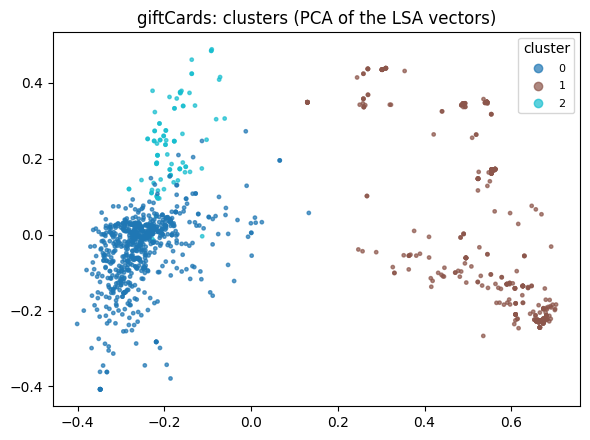

In [11]:
clusters = {k: cache.cached(k, "clustering", lambda k=k: clustering.run(meta[k])) for k in KEYS}

for k in KEYS:
    c = clusters[k]
    print(f"\n=== {k}: k = {c.k} ===")
    clustering.plot_k_selection(c.k_scores, k)
    plt.show()
    display(c.profile)
    for cid, titles in c.examples.items():
        print(f"cluster {cid}: " + " | ".join(titles))
    clustering.plot_clusters_2d(c.xy, c.xy_labels, k)
    plt.show()

**The clusters are clear product types**: wigs, nail art, hair bundles and skin care in All
Beauty; guitars, pedals and amplifiers, microphones, cables, drums and stage lights in
Musical Instruments; earrings, rings, wall prints and decals in Handmade Products.

**But the silhouette scores are low** (0.03-0.14) and mostly peak at k = 9-10, the upper end
of the range tried. Product texts don't form well-separated groups; they overlap gradually
(a "guitar strap" is both a guitar accessory and a strap). The chosen k gives readable
groups, not a natural number of clusters.

**Ratings differ by product type.** In All Beauty, hair bundles average 3.16 stars, with
54% of products below 3.5, and wigs 3.51, against 4.22 for bath and body products. In
Software, casino and slot apps are the worst-rated group (3.16; 70% below 3.5), and most
apps are free (median price 0). Musical Instruments and Handmade Products are rated
uniformly high (4.0-4.4 and 4.2-4.55 across clusters).

## 5. Recommendation

Task: predict the product each user reviews next. The data is reduced to its 5-core
(users and products with at least 5 reviews). For every user, the last review is held
out for the test and the one before it for validation. Models score all products the
user hasn't reviewed; HR@10 is the share of users whose held-out product is in the top
10, and NDCG@10 also rewards ranking it higher. The hybrid's weight is chosen on the
validation reviews and then reported on the test reviews.

In [12]:
recs = {k: cache.cached(k, "recommendation", lambda k=k: recommend.run(ratings[k], meta[k]))
        for k in KEYS}

display(pd.DataFrame({k: r.stats for k, r in recs.items() if r is not None}).T)
for k, r in recs.items():
    if r is not None:
        print(f"\n=== {k} ===")
        display(r.table)

,reviews (all),reviews (5-core),users,products,density,evaluated users
allBeauty,701528.0,2535.0,253.0,356.0,0.028145,253.0
software,4880181.0,1276840.0,146396.0,17591.0,0.000496,5000.0
musicalInstruments,3017439.0,511836.0,57439.0,24587.0,0.000362,5000.0
giftCards,152410.0,2429.0,377.0,129.0,0.049946,377.0



=== allBeauty ===


,val HR@10,val NDCG@10,test HR@10,test NDCG@10
model,,,,
Popularity,0.0138,0.0046,0.0079,0.0044
User-based CF,0.0395,0.0200,0.0632,0.0331
Item-based CF,0.0909,0.0399,0.0870,0.0510
Content-based,0.0791,0.0425,0.0791,0.0427
Hybrid (0.5 Item-based CF + 0.5 Content-based),0.0949,0.0523,0.1107,0.0517



=== software ===


,val HR@10,val NDCG@10,test HR@10,test NDCG@10
model,,,,
Popularity,0.0602,0.0292,0.0670,0.0347
User-based CF,0.1461,0.0822,0.1487,0.0846
Item-based CF,0.1530,0.0851,0.1506,0.0824
Content-based,0.0272,0.0132,0.0263,0.0125
Hybrid (0.6 Item-based CF + 0.4 Content-based),0.1534,0.0857,0.1502,0.0819



=== musicalInstruments ===


,val HR@10,val NDCG@10,test HR@10,test NDCG@10
model,,,,
Popularity,0.0304,0.0155,0.0286,0.0141
User-based CF,0.0423,0.0254,0.0456,0.0267
Item-based CF,0.0187,0.0115,0.0232,0.0144
Content-based,0.0068,0.0036,0.0082,0.0045
Hybrid (0.2 Item-based CF + 0.8 Content-based),0.0266,0.0147,0.0292,0.0173



=== giftCards ===


,val HR@10,val NDCG@10,test HR@10,test NDCG@10
model,,,,
Popularity,0.4164,0.2516,0.4257,0.2550
User-based CF,0.4810,0.2853,0.5172,0.3095
Item-based CF,0.4218,0.2492,0.4801,0.2843
Content-based,0.1499,0.0789,0.1936,0.1052
Hybrid (0.7 Item-based CF + 0.3 Content-based),0.4324,0.2515,0.4668,0.2912


The 5-cores show how sparse the data is: Software keeps 146k users and Musical
Instruments 57k, but All Beauty keeps only 253 users and Gift Cards 377, and Handmade
Products has too few to evaluate. The scores are low in absolute terms because every
model ranks the whole catalog (17,000-25,000 products) and gets one try per user.

- **Collaborative filtering beats popularity** in Software (HR@10 0.15 against 0.07) and
  Gift Cards (0.52 against 0.43). In Musical Instruments only user-based CF does
  (0.046 against 0.029); item-based CF is below popularity there.
- **Content-based is the weakest** wherever there is enough data: apps and instruments
  with similar descriptions are not what the same people buy.
- **The hybrid** helps a little in All Beauty (0.11 against 0.09), but with 253 users
  that difference is within noise. Elsewhere it doesn't beat the best CF model.
- Validation and test scores agree closely, so the hybrid's weight was not overfitted.

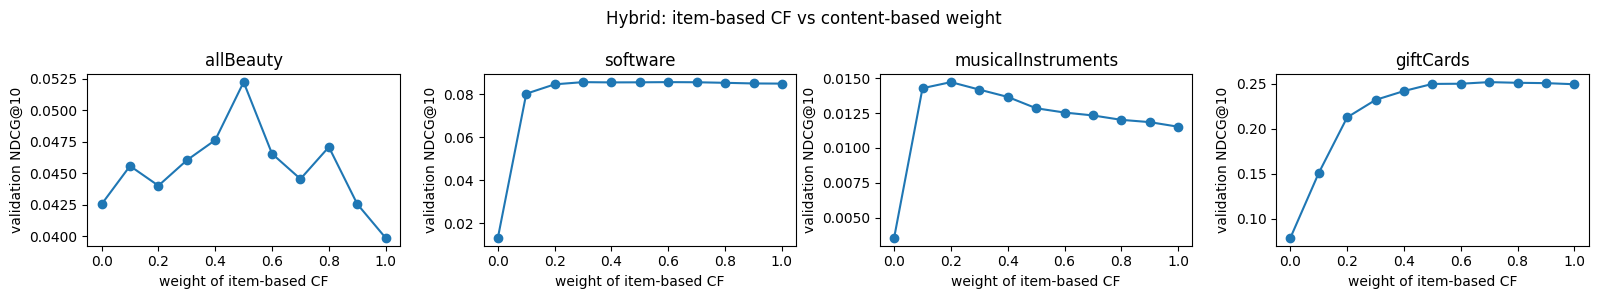

In [13]:
done = {k: r for k, r in recs.items() if r is not None}
fig, axes = plt.subplots(1, len(done), figsize=(4 * len(done), 3), squeeze=False)
for ax, (k, r) in zip(axes.flat, done.items()):
    ax.plot(r.weights["weight of item-based CF"], r.weights["NDCG@10"], marker="o")
    ax.set_title(k)
    ax.set_xlabel("weight of item-based CF")
    ax.set_ylabel("validation NDCG@10")
fig.suptitle("Hybrid: item-based CF vs content-based weight")
fig.tight_layout()
plt.show()

Example: what the hybrid recommends to one user.

In [14]:
k = max((k for k in KEYS if recs[k] is not None), key=lambda k: recs[k].stats["users"])
history, recommended = recommend.recommend(recs[k], meta[k], user_index=0)
print(f"Category: {k}\n\nReviewed:")
print("\n".join("  - " + t[:100] for t in history))
print("\nRecommended:")
print("\n".join("  - " + t[:100] for t in recommended))

Category: software

Reviewed:
  - Windows 98: Second Edition
  - Weather
  - HISTORY
  - [Old Version] TurboTax Home and Business Fed + Efile + State 2013
  - Pluto TV - It’s Free TV
  - TurboTax Home & Business 2014 Fed + State + Fed Efile Tax Software - Win [Download] OLD VERSION
  - Microsoft Windows 10 Home USB Flash Drive [Old Version]
  - Paramount+
  - ID GO - Fire TV
  - CNN

Recommended:
  - NBC
  - The CW
  - A&E
  - AMC
  - YouTube
  - Downloader
  - Watch TBS
  - NFL
  - USA Network
  - FOX Sports: Stream live USFL, MLB, NASCAR, Soccer and more. Plus get scores and news!


A user who reviewed streaming apps (Pluto TV, Paramount+, CNN) gets other channel apps
(NBC, The CW, A&E, AMC). Sensible, if unsurprising.

## 6. Sentiment classification

Labels from the stars (1-2 negative, 3 neutral, 4-5 positive); features from the text
only: TF-IDF of the cleaned review (words and word pairs) or the average GloVe embedding,
plus the VADER score. The stars and every score derived from them are excluded: with them
as features, a model reads the label instead of predicting it, which is how an earlier
version of this analysis reached 99.99% accuracy.

80/20 stratified split; 5-fold cross-validation on the 80%; one final evaluation on the
20%. Classes are imbalanced, so the main metric is macro-F1, and the majority-class
baseline shows how much accuracy alone is worth.

In [15]:
import gc
del recs, clusters, ratings   # not needed below: free memory for the classifiers
gc.collect()

display(pd.DataFrame({k: classify.class_shares(reviews[k]) for k in KEYS}).T)
glove = classify.load_glove()
cls = {k: cache.cached(k, "classification", lambda k=k: classify.evaluate(reviews[k], glove))
       for k in KEYS}

,negative,neutral,positive
allBeauty,0.206,0.081,0.713
software,0.189,0.086,0.726
musicalInstruments,0.131,0.065,0.805
handmadeProducts,0.093,0.045,0.862
giftCards,0.093,0.021,0.885


In [16]:
for k in KEYS:
    print(f"\n=== {k} ===")
    display(cls[k][0].set_index(["features", "model"]))


=== allBeauty ===


CV accuracy  CV macro-F1  CV macro-F1 std  test accuracy  test precision  test recall  test macro-F1
features model                                                                                                                    
TF-IDF   Majority class            0.7127       0.2774           0.0000         0.7126          0.2376       0.3333         0.2774
         Naive Bayes               0.8309       0.5419           0.0020         0.8366          0.7361       0.5505         0.5553
         Logistic Regression       0.8135       0.6691           0.0013         0.8180          0.6641       0.7066         0.6755
         KNN                       0.7863       0.4744           0.0026         0.7905          0.6896       0.4677         0.4838
         Random Forest             0.8334       0.6553           0.0045         0.8380          0.6646       0.6654         0.6614
GloVe    Majority class            0.7127       0.2774           0.0000         0.7126          0.2376       0.3333         0.2774
         Naive Bayes               0.5866       0.5060           0.0058         0.5858          0.5476       0.5626         0.5036
         Logistic Regression       0.7432       0.6103           0.0010         0.7512          0.6176       0.6582         0.6167
         KNN                       0.8127       0.5272           0.0016         0.8163          0.6664       0.5227         0.5328
         Random Forest             0.8272       0.5505           0.0037         0.8292          0.6554       0.5698         0.5555


=== software ===


CV accuracy  CV macro-F1  CV macro-F1 std  test accuracy  test precision  test recall  test macro-F1
features model                                                                                                                    
TF-IDF   Majority class            0.7257       0.2803           0.0000         0.7256          0.2419       0.3333         0.2803
         Naive Bayes               0.8245       0.5375           0.0035         0.8260          0.6982       0.5468         0.5421
         Logistic Regression       0.7896       0.6493           0.0054         0.7912          0.6365       0.6882         0.6510
         KNN                       0.7728       0.4793           0.0047         0.7762          0.6457       0.4639         0.4770
         Random Forest             0.8162       0.6417           0.0047         0.8169          0.6371       0.6613         0.6442
GloVe    Majority class            0.7257       0.2803           0.0000         0.7256          0.2419       0.3333         0.2803
         Naive Bayes               0.6666       0.5252           0.0034         0.6692          0.5192       0.5798         0.5284
         Logistic Regression       0.7312       0.5994           0.0062         0.7351          0.6010       0.6515         0.6052
         KNN                       0.8170       0.5564           0.0077         0.8189          0.6477       0.5576         0.5638
         Random Forest             0.8156       0.5632           0.0072         0.8204          0.6201       0.5738         0.5703


=== musicalInstruments ===


CV accuracy  CV macro-F1  CV macro-F1 std  test accuracy  test precision  test recall  test macro-F1
features model                                                                                                                    
TF-IDF   Majority class            0.8048       0.2973           0.0000         0.8048          0.2683       0.3333         0.2973
         Naive Bayes               0.8641       0.5149           0.0017         0.8706          0.8159       0.5153         0.5316
         Logistic Regression       0.8325       0.6429           0.0037         0.8358          0.6313       0.7029         0.6536
         KNN                       0.8367       0.4377           0.0028         0.8410          0.6750       0.4307         0.4526
         Random Forest             0.8634       0.6259           0.0048         0.8664          0.6389       0.6508         0.6357
GloVe    Majority class            0.8048       0.2973           0.0000         0.8048          0.2683       0.3333         0.2973
         Naive Bayes               0.5690       0.4705           0.0030         0.5647          0.5199       0.5555         0.4714
         Logistic Regression       0.7484       0.5754           0.0041         0.7510          0.5760       0.6485         0.5817
         KNN                       0.8564       0.5088           0.0030         0.8614          0.6214       0.5077         0.5214
         Random Forest             0.8566       0.5188           0.0042         0.8618          0.6037       0.5243         0.5312


=== handmadeProducts ===


CV accuracy  CV macro-F1  CV macro-F1 std  test accuracy  test precision  test recall  test macro-F1
features model                                                                                                                    
TF-IDF   Majority class            0.8623       0.3087           0.0000         0.8623          0.2874       0.3333         0.3087
         Naive Bayes               0.9055       0.5234           0.0022         0.9103          0.7749       0.5179         0.5397
         Logistic Regression       0.8856       0.6586           0.0071         0.8884          0.6368       0.7264         0.6677
         KNN                       0.8891       0.4696           0.0032         0.8899          0.7011       0.4417         0.4757
         Random Forest             0.9009       0.6515           0.0070         0.9020          0.6325       0.6822         0.6530
GloVe    Majority class            0.8623       0.3087           0.0000         0.8623          0.2874       0.3333         0.3087
         Naive Bayes               0.7630       0.5463           0.0085         0.7641          0.5346       0.6520         0.5451
         Logistic Regression       0.8218       0.6092           0.0071         0.8256          0.6014       0.7052         0.6137
         KNN                       0.9073       0.5474           0.0057         0.9081          0.6744       0.5255         0.5522
         Random Forest             0.9103       0.5577           0.0046         0.9133          0.6588       0.5567         0.5629


=== giftCards ===


CV accuracy  CV macro-F1  CV macro-F1 std  test accuracy  test precision  test recall  test macro-F1
features model                                                                                                                    
TF-IDF   Majority class            0.8854       0.3131           0.0000         0.8854          0.2951       0.3333         0.3131
         Naive Bayes               0.9350       0.5566           0.0030         0.9358          0.5761       0.5491         0.5608
         Logistic Regression       0.8874       0.6080           0.0046         0.8843          0.5796       0.6871         0.6084
         KNN                       0.9004       0.4132           0.0055         0.9026          0.6018       0.3976         0.4225
         Random Forest             0.9099       0.5930           0.0069         0.9060          0.5530       0.6332         0.5832
GloVe    Majority class            0.8854       0.3131           0.0000         0.8854          0.2951       0.3333         0.3131
         Naive Bayes               0.7027       0.4231           0.0026         0.6954          0.4191       0.5366         0.4136
         Logistic Regression       0.7732       0.5302           0.0034         0.7716          0.5199       0.6592         0.5257
         KNN                       0.9274       0.5488           0.0037         0.9286          0.6258       0.5510         0.5534
         Random Forest             0.9127       0.5391           0.0099         0.9144          0.5920       0.5146         0.5442

In [17]:
summary = pd.concat({k: cls[k][0].set_index(["features", "model"])["test macro-F1"]
                     for k in KEYS}, axis=1)
summary.style.highlight_max(axis=0, color="#c6e5c6").format("{:.3f}")

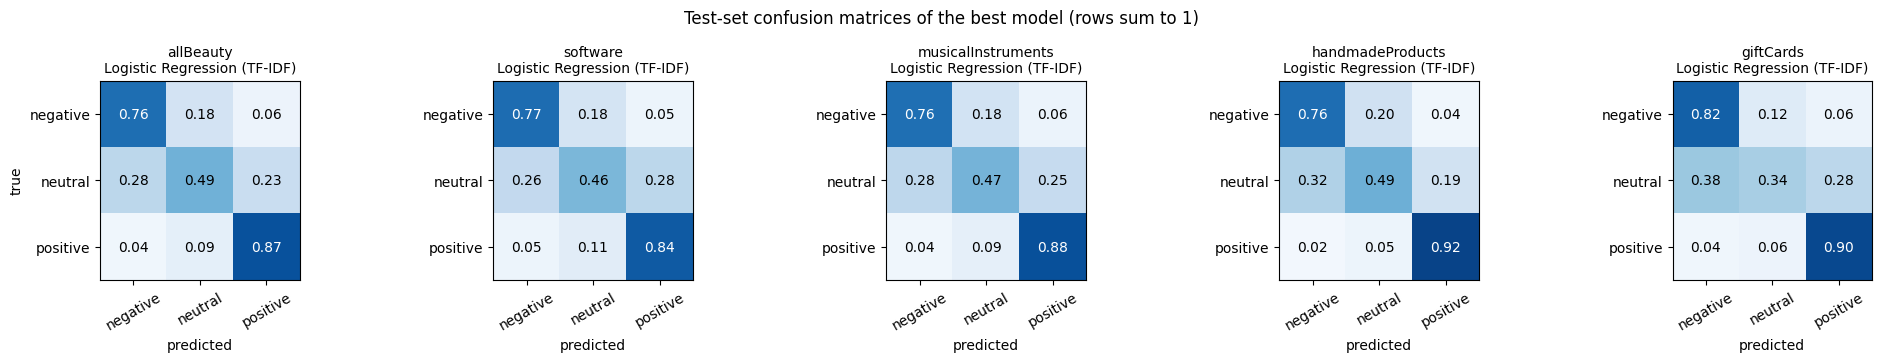

In [18]:
fig, axes = plt.subplots(1, len(KEYS), figsize=(4 * len(KEYS), 3.6))
for ax, k in zip(axes, KEYS):
    results, confusions = cls[k]
    best = results[results["model"] != "Majority class"].sort_values("test macro-F1").iloc[-1]
    cm = confusions[(best["features"], best["model"])]
    cm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3), classify.CLASSES, rotation=30)
    ax.set_yticks(range(3), classify.CLASSES)
    ax.set_title(f"{k}\n{best['model']} ({best['features']})", fontsize=10)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("true")
fig.suptitle("Test-set confusion matrices of the best model (rows sum to 1)")
fig.tight_layout()
plt.show()

- **Logistic regression on TF-IDF is the best model in all five categories**: test
  macro-F1 0.61-0.68, against 0.28-0.31 for the majority-class baseline. Cross-validation
  and test scores agree within about 0.01, so the estimates are stable.
- **Accuracy alone is misleading.** Predicting "positive" for everything already scores
  71-89%. Naive Bayes has a higher accuracy than logistic regression in every category,
  but a much lower macro-recall (0.52-0.55 against 0.69-0.73): it gets the frequent
  positive reviews right and misses many of the others, so its macro-F1 is 0.05-0.13 lower.
- **Neutral is the hard class**: about half of the 3-star reviews are recognized (a third
  for Gift Cards), and the rest are split between negative and positive. Negative reviews
  are found 76-82% of the time, positive ones 84-92%.
- **TF-IDF beats averaged GloVe embeddings** by 0.05-0.07 macro-F1. Averaging the word
  vectors of a review blurs exactly the words that carry the sentiment (*defective*,
  *refund*) and negations.
- With the stars as a feature, as in the first version of this project, these models
  reached 0.9999. From the text alone, about 0.68 is the realistic level.

## Summary

| Task | Result |
|---|---|
| Ratings | J-shaped, 55-84% five stars; lower in 2022-2023 than in 2020 |
| Sentiment scores | VADER agrees with the stars on 87-94% of clear reviews |
| Clustering | coherent product types; ratings differ by type (casino apps, hair bundles lowest) |
| Recommendation | CF beats popularity where there is enough data (Software HR@10 0.15 vs 0.07) |
| Classification | TF-IDF + logistic regression, macro-F1 0.61-0.68 vs 0.28-0.31 baseline |